In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
#from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

from google.colab import drive
drive.mount('/gdrive/')

# 현재 폴더로 이동
%cd /gdrive/MyDrive/

import pandas as pd

ipath = '/gdrive/MyDrive/'

# Read in data as pandas dataframe and display first 5 rows
features = pd.read_csv('/gdrive/MyDrive/temps.csv')


# === 1. 데이터 불러오기 ===


# === 2. 입력(X), 타겟(y) 설정 ===
X = features.drop(columns=["actual","week"])  # 'actual'은 예측 대상, 'week'는 범주형이라 제외
y = features["actual"]

# === 3. 학습/테스트 데이터 분할 ===
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=42
)

# === 4. 모델 정의 ===
dt_model = DecisionTreeRegressor(random_state=42)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# === 5. 학습 ===
dt_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

# === 6. 예측 ===
y_pred_dt = dt_model.predict(X_test)
y_pred_rf = rf_model.predict(X_test)

# === 7. 성능 평가 ===
print("Decision Tree")
print("MSE:", mean_squared_error(y_test, y_pred_dt))
print("R²:", r2_score(y_test, y_pred_dt))

print("\nRandom Forest")
print("MSE:", mean_squared_error(y_test, y_pred_rf))
print("R²:", r2_score(y_test, y_pred_rf))

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.



Drive already mounted at /gdrive/; to attempt to forcibly remount, call drive.mount("/gdrive/", force_remount=True).
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/IPython/core/interactiveshell.py", line 3553, in run_code
    exec(code_obj, self.user_global_ns, self.user_ns)
  File "/tmp/ipython-input-2474490681.py", line 11, in <cell line: 0>
    get_ipython().run_line_magic('cd', '/gdrive/MyDrive/')
  File "/usr/local/lib/python3.12/dist-packages/IPython/core/interactiveshell.py", line 2418, in run_line_magic
    result = fn(*args, **kwargs)
             ^^^^^^^^^^^^^^^^^^^
  File "<decorator-gen-85>", line 2, in cd
  File "/usr/local/lib/python3.12/dist-packages/IPython/core/magic.py", line 187, in <lambda>
    call = lambda f, *a, **k: f(*a, **k)
                              ^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/IPython/core/magics/osm.py", line 342, in cd
    oldcwd = os.getcwd()
             ^^^^^^^^^^^
OSError: [Errno 107

Decision Tree RMSE: 6.6682469391421995
Random Forest RMSE: 4.5543353729885965


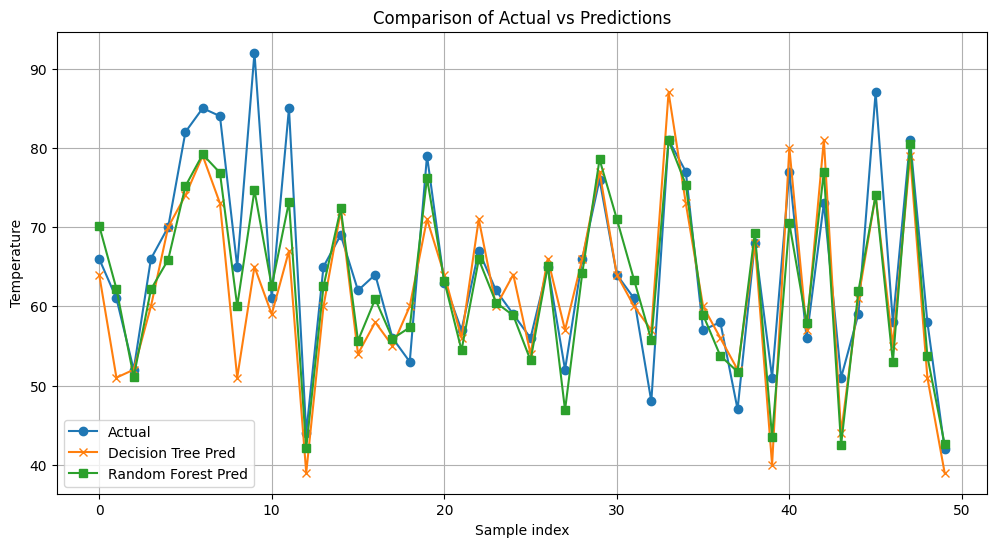

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np # Import numpy

# 데이터 불러오기
# Data loading and train/test split are already done in the previous cell,
# so we don't need to repeat it here.

# X_train, X_test, y_train, y_test = train_test_split(
#     X, y, test_size=0.2, random_state=42
# )

# Decision Tree
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)
dt_preds = dt_model.predict(X_test)

# Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

# 성능 평가
print("Decision Tree RMSE:", np.sqrt(mean_squared_error(y_test, dt_preds))) # Calculate RMSE using np.sqrt
print("Random Forest RMSE:", np.sqrt(mean_squared_error(y_test, rf_preds))) # Calculate RMSE using np.sqrt

# ---------------- 그래프 ----------------
plt.figure(figsize=(12,6))

# 실제값 vs Decision Tree 예측
plt.plot(y_test.values[:50], label="Actual", marker="o")
plt.plot(dt_preds[:50], label="Decision Tree Pred", marker="x")
plt.plot(rf_preds[:50], label="Random Forest Pred", marker="s")

plt.title("Comparison of Actual vs Predictions")
plt.xlabel("Sample index")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

from google.colab import drive
drive.mount('/gdrive/')

# 현재 폴더로 이동
%cd /gdrive/MyDrive/

import pandas as pd

ipath = '/gdrive/MyDrive/'

# Read in data as pandas dataframe and display first 5 rows
df = pd.read_csv('/gdrive/MyDrive/temps.csv')


# week 변수(Label Encoding)
le = LabelEncoder()
df["week"] = le.fit_transform(df["week"])

# 입력(X), 타겟(y) 분리
X = df.drop("actual", axis=1)
y = df["actual"]

# train-test 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 랜덤 포레스트 모델
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 예측
y_pred = model.predict(X_test)

# 평가 지표
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("R²:", r2)


Drive already mounted at /gdrive/; to attempt to forcibly remount, call drive.mount("/gdrive/", force_remount=True).
/gdrive/MyDrive
MSE: 25.76398285714285
R²: 0.8157416309564122


Decision Tree RMSE: 6.6682469391421995
Random Forest RMSE: 4.5543353729885965


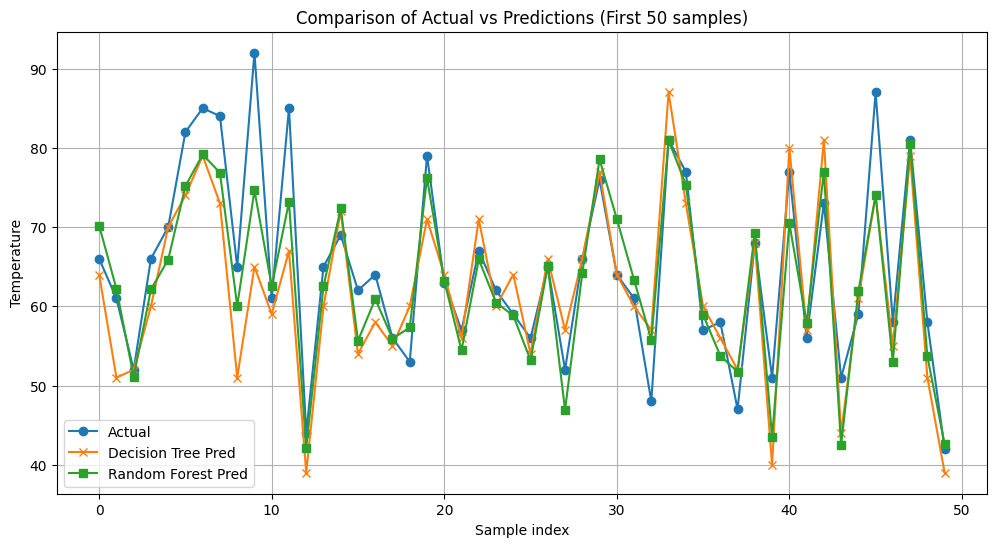

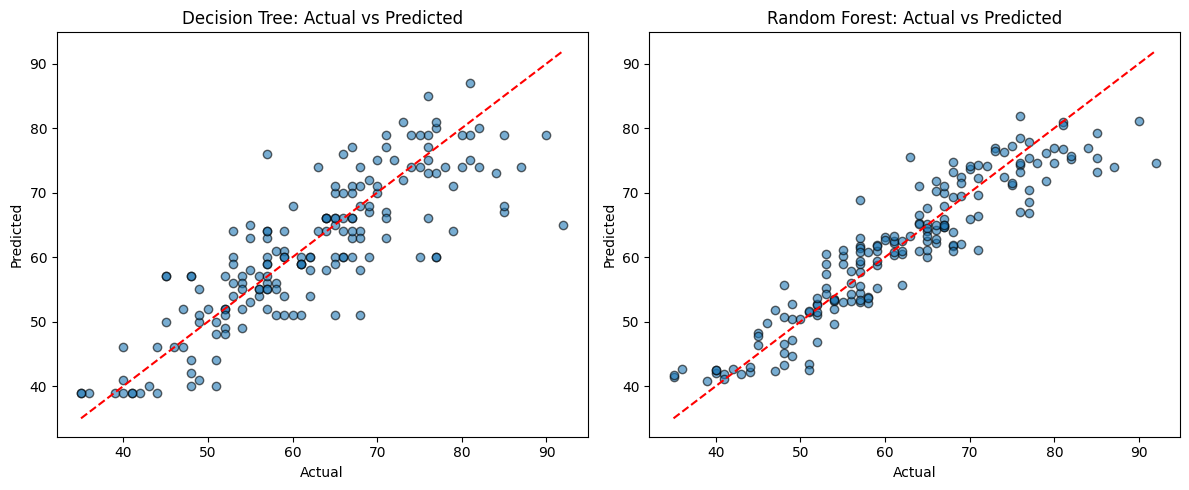

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np # Import numpy

# 데이터 불러오기
df = pd.read_csv("temps.csv")

# target과 features 분리
X = df.drop(columns=["actual", "week"])  # 요일(문자열) 제거
y = df["actual"]

# train/test 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=42
)

# Decision Tree
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)
dt_preds = dt_model.predict(X_test)

# Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

# 성능 평가
print("Decision Tree RMSE:", np.sqrt(mean_squared_error(y_test, dt_preds)))
print("Random Forest RMSE:", np.sqrt(mean_squared_error(y_test, rf_preds)))

# ---------------- 라인 그래프 ----------------
plt.figure(figsize=(12,6))
plt.plot(y_test.values[:50], label="Actual", marker="o")
plt.plot(dt_preds[:50], label="Decision Tree Pred", marker="x")
plt.plot(rf_preds[:50], label="Random Forest Pred", marker="s")
plt.title("Comparison of Actual vs Predictions (First 50 samples)")
plt.xlabel("Sample index")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True)
plt.show()

# ---------------- 산점도 ----------------
plt.figure(figsize=(12,5))

# Decision Tree 산점도
plt.subplot(1,2,1)
plt.scatter(y_test, dt_preds, alpha=0.6, edgecolor="k")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.title("Decision Tree: Actual vs Predicted")
plt.xlabel("Actual")
plt.ylabel("Predicted")

# Random Forest 산점도
plt.subplot(1,2,2)
plt.scatter(y_test, rf_preds, alpha=0.6, edgecolor="k")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.title("Random Forest: Actual vs Predicted")
plt.xlabel("Actual")
plt.ylabel("Predicted")

plt.tight_layout()
plt.show()

Decision Tree RMSE: 6.113217530190512
Random Forest RMSE: 5.0866338855587285

Feature Importances:
           Feature  Importance
4          temp_1    0.668063
5         average    0.175846
7    forecast_acc    0.042095
9          friend    0.024562
2             day    0.022444
6   forecast_noaa    0.020270
3          temp_2    0.017697
8  forecast_under    0.016336
1           month    0.012687
0            year    0.000000


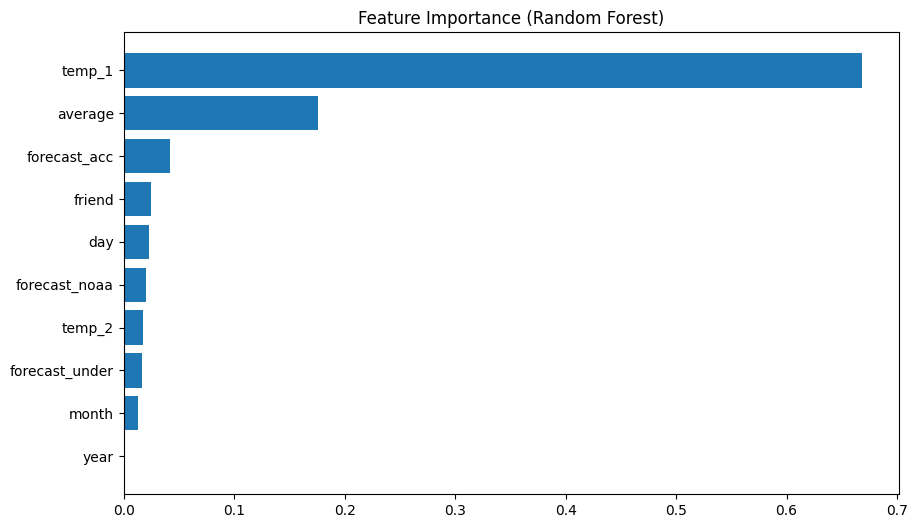

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import numpy as np # Import numpy

# 데이터 불러오기
df = pd.read_csv("/gdrive/MyDrive/temps.csv")

# target과 features 분리
X = df.drop(columns=["actual", "week"])  # 요일(문자열) 제거
y = df["actual"]

# train/test 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 모델 학습
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)
dt_preds = dt_model.predict(X_test)

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

rf_preds = rf_model.predict(X_test)

# 성능 평가
print("Decision Tree RMSE:", np.sqrt(mean_squared_error(y_test, dt_preds)))
print("Random Forest RMSE:", np.sqrt(mean_squared_error(y_test, rf_preds)))

# ---------------- Feature Importance ----------------
importances = rf_model.feature_importances_
feature_names = X.columns

# 데이터프레임으로 정리
feat_importances = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

print("\nFeature Importances:\n", feat_importances)

# 그래프
plt.figure(figsize=(10,6))
plt.barh(feat_importances["Feature"], feat_importances["Importance"])
plt.title("Feature Importance (Random Forest)")
plt.gca().invert_yaxis()  # 중요도가 높은 순으로 위에 오도록
plt.show()